## March 2026 
Here we will look at the transfer functions including also the anisotropic heating contribution


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
import math
from scipy.interpolate import CubicSpline 
import tol_colors as tc

import tools
import my_plot as mplt

In [2]:
def extract_custom_state_from_files(folder_path, ell, pattern="custom_state_kv_001_yn_aniso_system-all_wG.dat_ymax15_lmax25_adiabatic.dat"):
    """Extract custom transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" 
    file_path = next(folder.glob(pattern))
    
    theta = [[] for _ in range(ell+1)]
    mu = [[] for _ in range(ell+1)]
    y = [[] for _ in range(ell+1)]
    z = []
    
    data = np.loadtxt(file_path, comments='#')  
    z.extend(data[:, 0])  # First column is redshift
    for i in range(ell+1):
        theta[i].extend(data[:, 1+i*(ell)])   # All theta values from column 1 and multiples of it
        print( " theta ", i, "comes from column ", 1+i*(ell))
        y[i].extend(data[:, 2+i*(ell)])       # All y values from column 2 and multiples of it
        print( " y ", i, "comes from column ", 2+i*(ell))
        mu[i].extend(data[:, 3+i*(ell)])  # All mu values from column 3 and multiples of it
        print( " mu ", i, "comes from column ", 3+i*(ell))
    
    return z, np.array(theta), np.array(y), np.array(mu)

In [3]:
def extract_state_scattering_basis(folder_path, ell, ell_max, k, basis="scattering"):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) / "batch" / "FH" / "yn_T_aniso_system"
    file_path = []
    file_path2 = []
    # Collect multipole files (0,1,2,...)

    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_{i}.dat")))
        # theta values always come from the computational basis for the scattering
        file_path2.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_computation-basis_{i}.dat"))) 
    # Collect background file
    bg_file = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_bg.dat"))
    bg_file2 = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic.dat"))

    theta = [[] for _ in range(ell+3)]
    mu = [[] for _ in range(ell+2)]
    y = [[] for _ in range(ell+2)]
    a = []

    # Read header to find theta_corr_0 column (format: "name [col_num]")
    with open(bg_file2, 'r') as f:
        header_line = f.readline().strip('# \n')
        header = header_line.split()
    # Find column index for theta_corr_0: look for "theta_corr_0", then get number from next element "[N]"
    idx = header.index("theta_corr_0")
    theta_corr_col = int(header[idx + 1].strip('[]')) - 1  # Convert to 0-indexed

    # First: background
    data_bg = np.loadtxt(bg_file, comments='#')
    data_theta_bg = np.loadtxt(bg_file2, comments='#')
    a.extend(data_bg[:, 0])  # First column is redshift (only read once)
    theta[0].extend(data_theta_bg[:, 1])
    y[0].extend(data_bg[:, 2])
    mu[0].extend(data_bg[:, 9])

    # Then: multipoles
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#')
        data_theta = np.loadtxt(file_path2[i], comments='#')
        theta[i+1].extend(data_theta[:, 1])
        y[i+1].extend(data[:, 2])
        mu[i+1].extend(data[:, 9])
    
     # Load corrections to the monopole from the background file (dynamically found column)
    theta[-1].extend(data_theta_bg[:, theta_corr_col])

    return a, np.array(theta), np.array(y), np.array(mu)

In [4]:
def extract_state_scattering_basis_tf(folder_path, ell, ell_max, k, basis="scattering"):
    """Extract scattering basis transfer function data from files in a folder """
    folder = Path(folder_path) 
    file_path = []
    file_path2 = []
    # Collect multipole files (0,1,2,...)

    for i in range(ell+1):
        file_path.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_{i}.dat")))
        # theta values always come from the computational basis for the scattering
        file_path2.append(next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_computation-basis_{i}.dat"))) 
    # Collect background file
    bg_file = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic_scattering-basis_bg.dat"))
    bg_file2 = next(folder.glob(f"full_state_kv_{k}.dat_ymax15_lmax{ell_max}_adiabatic.dat"))

    theta = [[] for _ in range(ell+3)]
    mu = [[] for _ in range(ell+2)]
    y = [[] for _ in range(ell+2)]
    a = []

    # Read header to find theta_corr_0 column (format: "name [col_num]")
    with open(bg_file2, 'r') as f:
        header_line = f.readline().strip('# \n')
        header = header_line.split()
    # Find column index for theta_corr_0: look for "theta_corr_0", then get number from next element "[N]"
    idx = header.index("theta_corr_0")
    theta_corr_col = int(header[idx + 1].strip('[]')) - 1  # Convert to 0-indexed

    # First: background
    data_bg = np.loadtxt(bg_file, comments='#')
    data_theta_bg = np.loadtxt(bg_file2, comments='#')
    a.extend(data_bg[:, 0])  # First column is redshift (only read once)
    theta[0].extend(data_theta_bg[:, 1])
    y[0].extend(data_bg[:, 2])
    mu[0].extend(data_bg[:, 9])

    # Then: multipoles
    for i in range(ell+1):
        data = np.loadtxt(file_path[i], comments='#')
        data_theta = np.loadtxt(file_path2[i], comments='#')
        theta[i+1].extend(data_theta[:, 1])
        y[i+1].extend(data[:, 2])
        mu[i+1].extend(data[:, 9])
    
     # Load corrections to the monopole from the background file (dynamically found column)
    theta[-1].extend(data_theta_bg[:, theta_corr_col])

    return a, np.array(theta), np.array(y), np.array(mu)

In [5]:
kv_values = ["001", "002", "003"]
kv_values_Mpc = {"001" : 1, "002" : 0.1, "003" : 0.01, "004" : 0.001}
zcon = [5.0e6, 5.0e5, 5.0e4, 5.0e3]
m_dp = [0.000195304, 6.17608e-06, 6.17608e-06, 5.9625e-09] 

In [6]:
ell = 0
theta_noXe = []
y_noXe = []
mu_noXe = []
a_noXe = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_noXe/outputs-dp1.0", ell, 150, kv )
    
    theta_noXe.append(th)
    y_noXe.append(yy)
    mu_noXe.append(m)
    a_noXe.append(zt)

In [7]:
ell = 0
theta_noph = []
y_noph = []
mu_noph = []
a_noph = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.0", ell, 150, kv )
    
    theta_noph.append(th)
    y_noph.append(yy)
    mu_noph.append(m)
    a_noph.append(zt)

In [8]:
ell = 0
theta = []
y = []
mu = []
a = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.0_ph", ell, 150, kv )
    
    theta.append(th)
    y.append(yy)
    mu.append(m)
    a.append(zt)

In [9]:
def plot_transfer_functions(a, a_noph, a_noXe, theta, theta_noph, theta_noXe, y, y_noph, y_noXe, mu, mu_noph, mu_noXe, zcon, colors):
    fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)), sharey='row')
    fig.subplots_adjust(hspace=0, wspace=0)

    theta_bar = 1.7*1e-6
    # Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
    for col in range(len(kv_values)):  # columns for different kv values

        for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
            ax1[0,col].plot(a[col], 4*theta[col][-1]*1e5, color=colors[0], label="Standard case",  linestyle="-")
            ax1[0,col].plot(a_noph[col], 4*theta_noph[col][-1]*1e5, label = "No perturbed heating", color=colors[1],   linestyle="-")
            #ax1[0,col].plot(a_noXe[col], 4*theta_noXe[col][-1]*1e5, color=colors[2], label = "No evolution of Xe",  linestyle="-")

            ax1[1, col].plot(a[col], 4*y[col][ell_idx]*1e5,  color=colors[0],   linestyle="-")
            ax1[1, col].plot(a_noph[col], 4*y_noph[col][ell_idx]*1e5,  color=colors[1],   linestyle="-")
            #ax1[1, col].plot(a_noXe[col], 4*y_noXe[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

            ax1[2, col].plot(a[col], 1/1.401*mu[col][ell_idx]*1e5, color=colors[0],   linestyle="-")
            ax1[2, col].plot(a_noph[col], 1/1.401*mu_noph[col][ell_idx]*1e5,  color=colors[1],   linestyle="-")
            #ax1[2, col].plot(a_noXe[col], 1/1.401*mu_noXe[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

        

        ax1[0, col].set_title(f"k = {kv_values_Mpc[kv_values[col]]}" "${\\rm Mpc^{-1}}$")

    # Set labels for left column
    ax1[0, 0].set_ylabel("$\\delta \\theta $")
    ax1[1, 0].set_ylabel("$\\mu^{(1)}$")
    ax1[2, 0].set_ylabel("$y^{(1)}$")

    # Set x-labels for bottom row only
    for col in range(3):
        ax1[2, col].set_xlabel("a")

    # Remove x tick labels for top two rows
    for row in range(2):
        for col in range(3):
            ax1[row, col].tick_params(labelbottom=False)

    # Remove y tick labels for middle and right columns
    for row in range(3):
        for col in range(1, 3):
            ax1[row, col].tick_params(labelleft=False)

    # Apply formatting to all subplots
    for ax in ax1.flat:
        ax.set_xscale('log')
    
        ax.minorticks_on()
        ax.tick_params(direction='in', right=True, top=True)
        ax.tick_params(labelsize=12)
        ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
        ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
        ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

        ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


    # Add legend to first column subplots
    ax1[0, 0].legend()
    # ax1[1, 0].legend()
    # ax1[2, 0].legend()

    #  # Dynamically place annotation using axis proportions
    # xlim = ax1[2, 0].get_xlim()
    # ylim = ax1[2, 0].get_ylim()
    # x_annot = xlim[0] + 0.005 * (xlim[1] - xlim[0])  # 5% from left
    # y_annot = ylim[0] + 0.1 * (ylim[1] - ylim[0])   # 10% from bottom
    # ax1[2, 0].annotate(f"$m_{{\\rm dp}}$ = {tools.sci_notation(m_dp)}", xy=(x_annot, y_annot), fontsize=12)

    plt.tight_layout() 
    plt.savefig(f'outputs/transfer_functions_zcon{np.log10(zcon/5):.0f}.pdf', dpi=300, bbox_inches="tight")
    plt.show()

In [10]:
def plot_transfer_functions_ph(a, a_noph, theta, theta_noph, y, y_noph, mu, mu_noph, m_dp, zcon, colors):
    fig, ax1 = plt.subplots(1, 3, figsize=mplt.set_size(mplt.width*3, 1, (1,3)), sharey='row')
    fig.subplots_adjust(hspace=0, wspace=0)

    theta_bar = 1.7*1e-6
        # Loop over columns (kv = 001, 002, 003) and rows (ell = 1, 2, 3)
        

    for ell_idx in range(1, ell+2):  # ell multipoles 1, 2, 3
        print("Plotting ell ", ell_idx)
        ax1[0].plot(a, 4*theta[-1]*1e5, color=colors[0], label="Full Solution",  linestyle="-")
        ax1[0].plot(a_noph, 4*theta_noph[-1]*1e5, label = "No perturbed heating", color=colors[1],   linestyle="-")
        #ax1[0].plot(a_noXe[col], 4*theta_noXe[col][-1]*1e5, color=colors[2], label = "No evolution of Xe",  linestyle="-")

        ax1[1].plot(a, 1/1.401*mu[ell_idx]*1e5, color=colors[0],   linestyle="-")
        ax1[1].plot(a_noph, 1/1.401*mu_noph[ell_idx]*1e5,  color=colors[1],   linestyle="-")
        #ax1[2, col].plot(a_noXe[col], 1/1.401*mu_noXe[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

        ax1[2].plot(a, 4*y[ell_idx]*1e5,  color=colors[0],   linestyle="-")
        ax1[2].plot(a_noph, 4*y_noph[ell_idx]*1e5,  color=colors[1],   linestyle="-")
        #ax1[1, col].plot(a_noXe[col], 4*y_noXe[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

        

        

        ax1[0].set_title(f"k = 0.1" "${\\rm Mpc^{-1}}$")

    # Set labels for left column
    ax1[0].set_ylabel("$\\delta \\Theta \\times 10^5$")
    ax1[1].set_ylabel("$\\mu^{(1)} \\times 10^5$")
    ax1[2].set_ylabel("$y^{(1)} \\times 10^5$")

    # Set x-labels for bottom row only
    for col in range(3):
        ax1[col].set_xlabel("a")

    # Remove x tick labels for top two rows
    
    for col in range(3):
        ax1[col].tick_params()

    # Remove y tick labels for middle and right columns
    
    for col in range(1, 3):
        ax1[col].tick_params(labelleft=False)

    # Apply formatting to all subplots
    for ax in ax1.flat:
        ax.set_xscale('log')
    
        ax.minorticks_on()
        ax.tick_params(direction='in', right=True, top=True)
        ax.tick_params(labelsize=12)
        ax.tick_params(direction='in', which='minor', length=5, bottom=True, top=True, left=True, right=True)
        ax.tick_params(direction='in', which='major', length=10, bottom=True, top=True, left=True, right=True)
        ax.grid(True, which='both', linestyle='--', linewidth=0.3, alpha=0.7)

        ax.axvline(x= 1 / (1+zcon), color='gray', linestyle='dashed', linewidth=1)


    # Add legend to first column subplots
    ax1[0].legend()
    # ax1[1, 0].legend()
    # ax1[2, 0].legend()

    #  # Dynamically place annotation using axis proportions
    xlim = ax1[0].get_xlim()
    ylim = ax1[0].get_ylim()
    x_annot = xlim[0] + 0.01 * (xlim[1] - xlim[0])  # 5% from left
    y_annot = ylim[0] + 0.1 * (ylim[1] - ylim[0])   # 10% from bottom
    ax1[0].annotate(f"$m_{{\\rm dp}}$ = {tools.sci_notation(m_dp)} \n $z_{{\\rm con}}$ = {tools.sci_notation(zcon)} ", xy=(x_annot, y_annot), fontsize=12)

    plt.tight_layout() 
    #plt.savefig(f'outputs/transfer_functions_zcon{np.log10(zcon/5):.0f}.pdf', dpi=300, bbox_inches="tight")
    plt.show()

Plotting ell  1


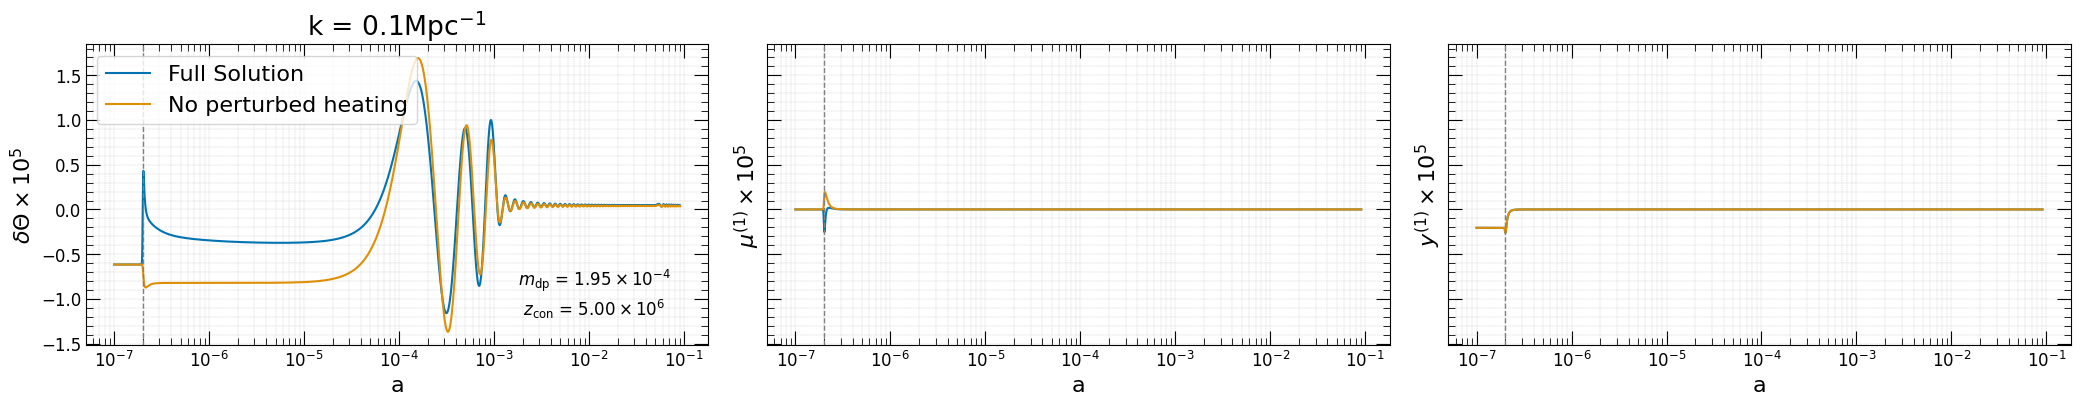

In [11]:
colors = mplt.set_colors(4, palette="colorblind")
colors2 = tc.colorsets['light']

#plot_transfer_functions(a, a_noph, a_noXe, theta, theta_noph, theta_noXe, y, y_noph, y_noXe, mu, mu_noph, mu_noXe, zcon, colors)
plot_transfer_functions_ph(a[1], a_noph[1], theta[1], theta_noph[1], y[1], y_noph[1], mu[1], mu_noph[1], m_dp[0],zcon[0], colors)

In [12]:
ell = 0
theta_noXe1 = []
y_noXe1 = []
mu_noXe1 = []
a_noXe1 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_noXe/outputs-dp1.1", ell, 150, kv )
    theta_noXe1.append(th)
    y_noXe1.append(yy)
    mu_noXe1.append(m)
    a_noXe1.append(zt)

theta_noph1 = []
y_noph1 = []
mu_noph1 = []
a_noph1 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.1", ell, 150, kv )
    theta_noph1.append(th)
    y_noph1.append(yy)
    mu_noph1.append(m)
    a_noph1.append(zt)

In [13]:
theta_1 = []
y_1 = []
mu_1 = []
a_1 = []

for kv in kv_values:
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso-nah1.1/", ell, kv )
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.1_ph", ell, 150, kv )
    
    theta_1.append(th)
    y_1.append(yy)
    mu_1.append(m)
    a_1.append(zt)

Plotting ell  1


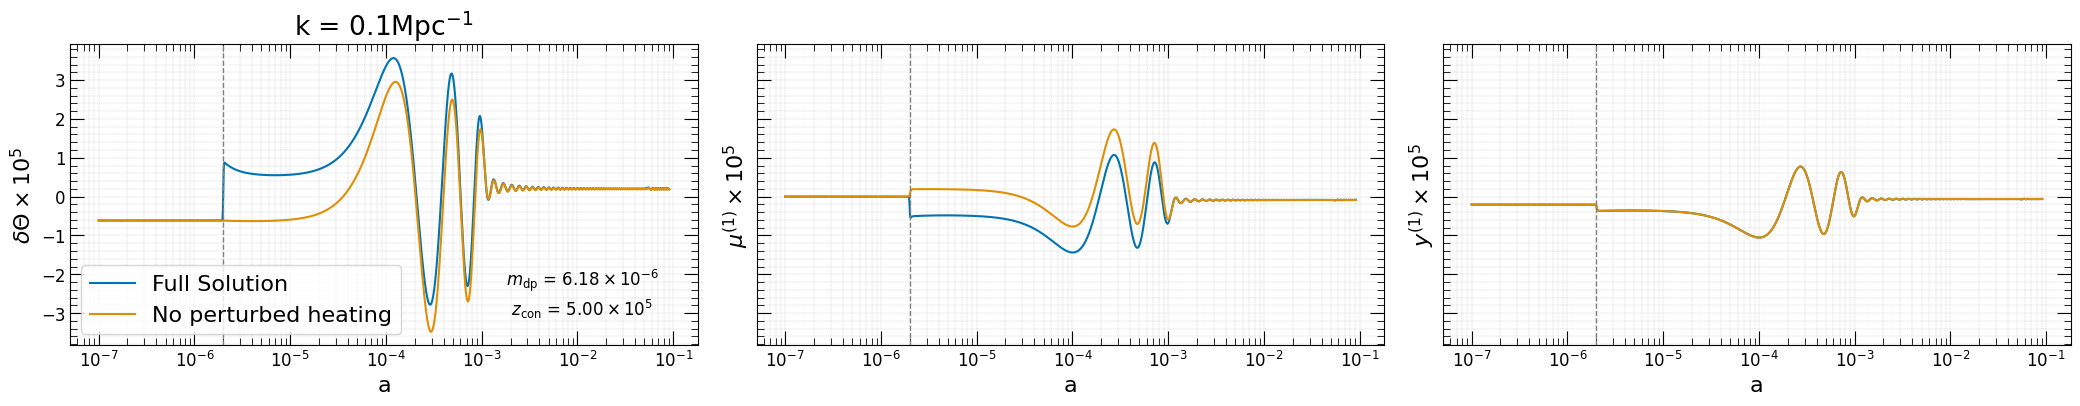

In [14]:

#plot_transfer_functions(a_1, a_noph1, a_noXe1, theta_1, theta_noph1, theta_noXe1, y_1, y_noph1, y_noXe1, mu_1, mu_noph1, mu_noXe1, zcon, colors)
plot_transfer_functions_ph(a_1[1], a_noph1[1], theta_1[1], theta_noph1[1], y_1[1], y_noph1[1], mu_1[1], mu_noph1[1], m_dp[1], zcon[1], colors)

In [15]:
ell = 0
theta_noXe2 = []
y_noXe2 = []
mu_noXe2 = []
a_noXe2 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_noXe/outputs-dp1.2", ell, 150, kv )
    theta_noXe2.append(th)
    y_noXe2.append(yy)
    mu_noXe2.append(m)
    a_noXe2.append(zt)

theta_noph2 = []
y_noph2 = []
mu_noph2 = []
a_noph2 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.2", ell, 150, kv )
    theta_noph2.append(th)
    y_noph2.append(yy)
    mu_noph2.append(m)
    a_noph2.append(zt)

In [16]:
theta_2 = []
y_2 = []
mu_2 = []
a_2 = []

for kv in kv_values:
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso-nah1.1/", ell, kv )
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.2_ph", ell, 150, kv )
    
    theta_2.append(th)
    y_2.append(yy)
    mu_2.append(m)
    a_2.append(zt)

Plotting ell  1


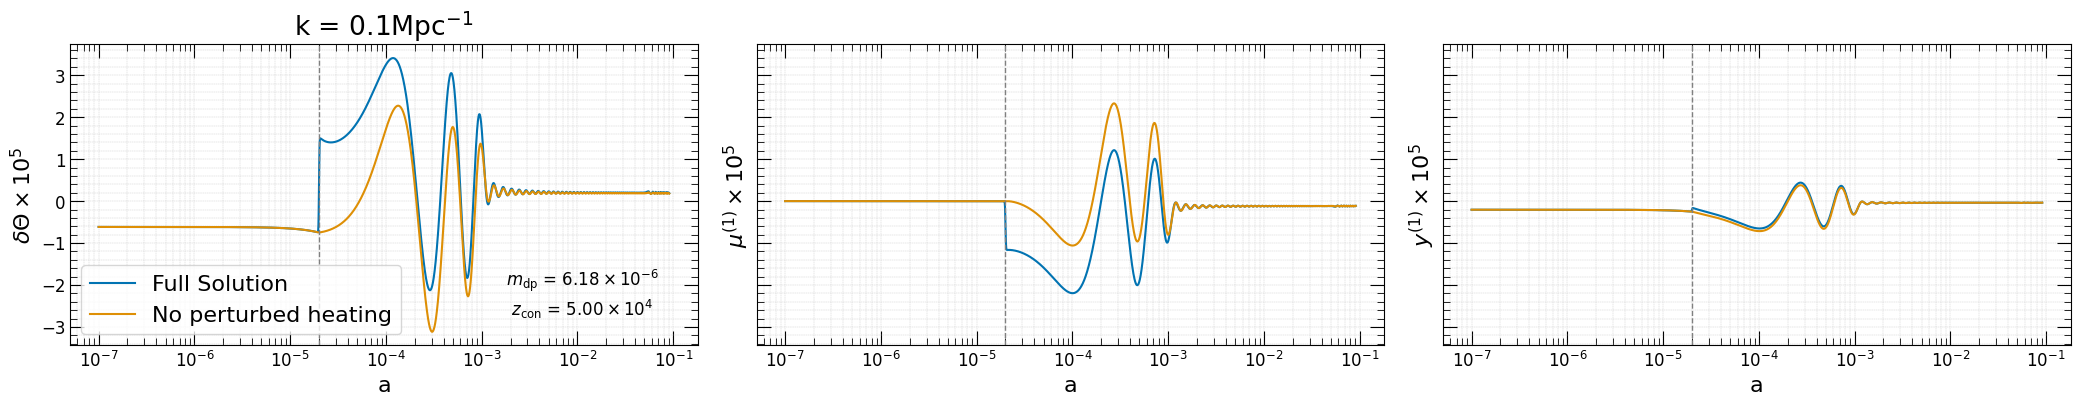

In [17]:

#plot_transfer_functions(a_2, a_noph2, a_noXe2, theta_2, theta_noph2, theta_noXe2, y_2, y_noph2, y_noXe2, mu_2, mu_noph2, mu_noXe2, zcon, colors)
plot_transfer_functions_ph(a_2[1], a_noph2[1], theta_2[1], theta_noph2[1], y_2[1], y_noph2[1], mu_2[1], mu_noph2[1], m_dp[2], zcon[2], colors)

In [18]:
ell = 0
theta_noXe3 = []
y_noXe3 = []
mu_noXe3 = []
a_noXe3 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_noXe/outputs-dp1.3", ell, 150, kv )
    theta_noXe3.append(th)
    y_noXe3.append(yy)
    mu_noXe3.append(m)
    a_noXe3.append(zt)

theta_noph3 = []
y_noph3 = []
mu_noph3 = []
a_noph3 = []

for kv in kv_values:
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.3", ell, 150, kv )
    theta_noph3.append(th)
    y_noph3.append(yy)
    mu_noph3.append(m)
    a_noph3.append(zt)

In [19]:
theta_3 = []
y_3 = []
mu_3 = []
a_3 = []

for kv in kv_values:
    #zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/dp-aniso-nah1.1/", ell, kv )
    zt, th, yy, m = extract_state_scattering_basis("../Data/Dark-photons/output_dp_ell/outputs-dp1.3_ph", ell, 150, kv )
    
    theta_3.append(th)
    y_3.append(yy)
    mu_3.append(m)
    a_3.append(zt)

Plotting ell  1


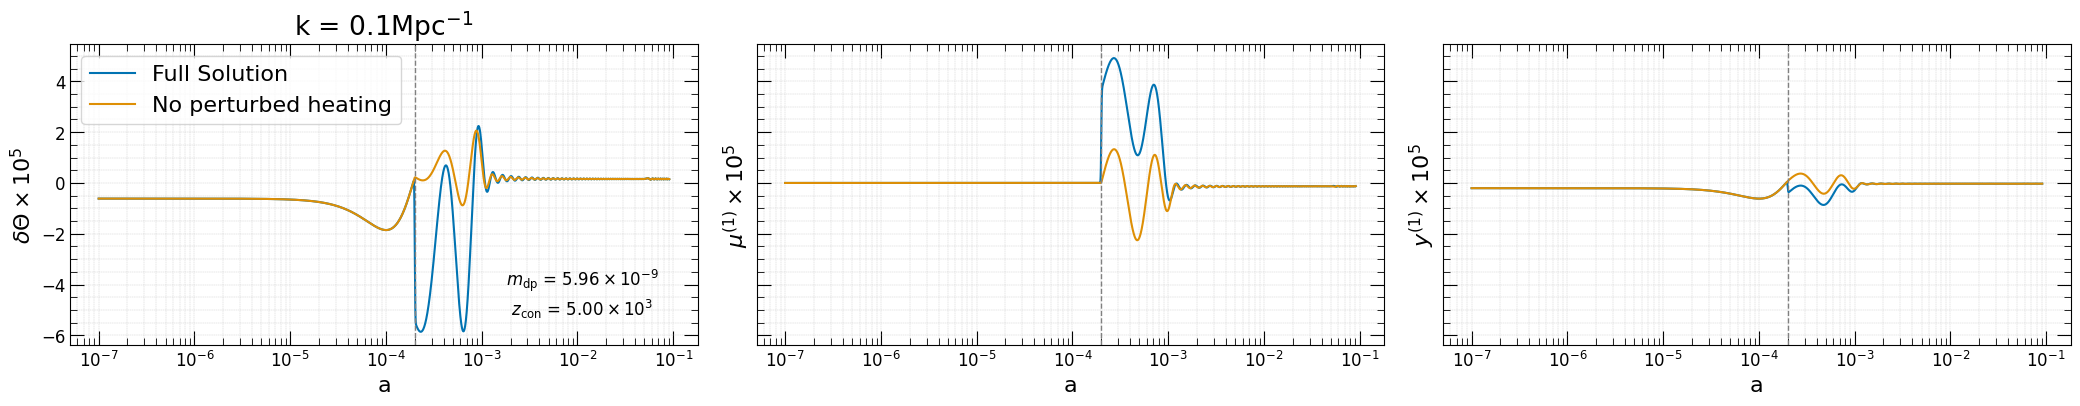

In [20]:
#plot_transfer_functions(a_3, a_noph3, a_noXe3, theta_3, theta_noph3, theta_noXe3, y_3, y_noph3, y_noXe3, mu_3, mu_noph3, mu_noXe3, zcon, colors)
plot_transfer_functions_ph(a_3[1], a_noph3[1], theta_3[1], theta_noph3[1], y_3[1], y_noph3[1], mu_3[1], mu_noph3[1], m_dp[3], zcon[3], colors)

In [21]:
zcon = [ 5.0e5, 5.0e4, 5.0e3]

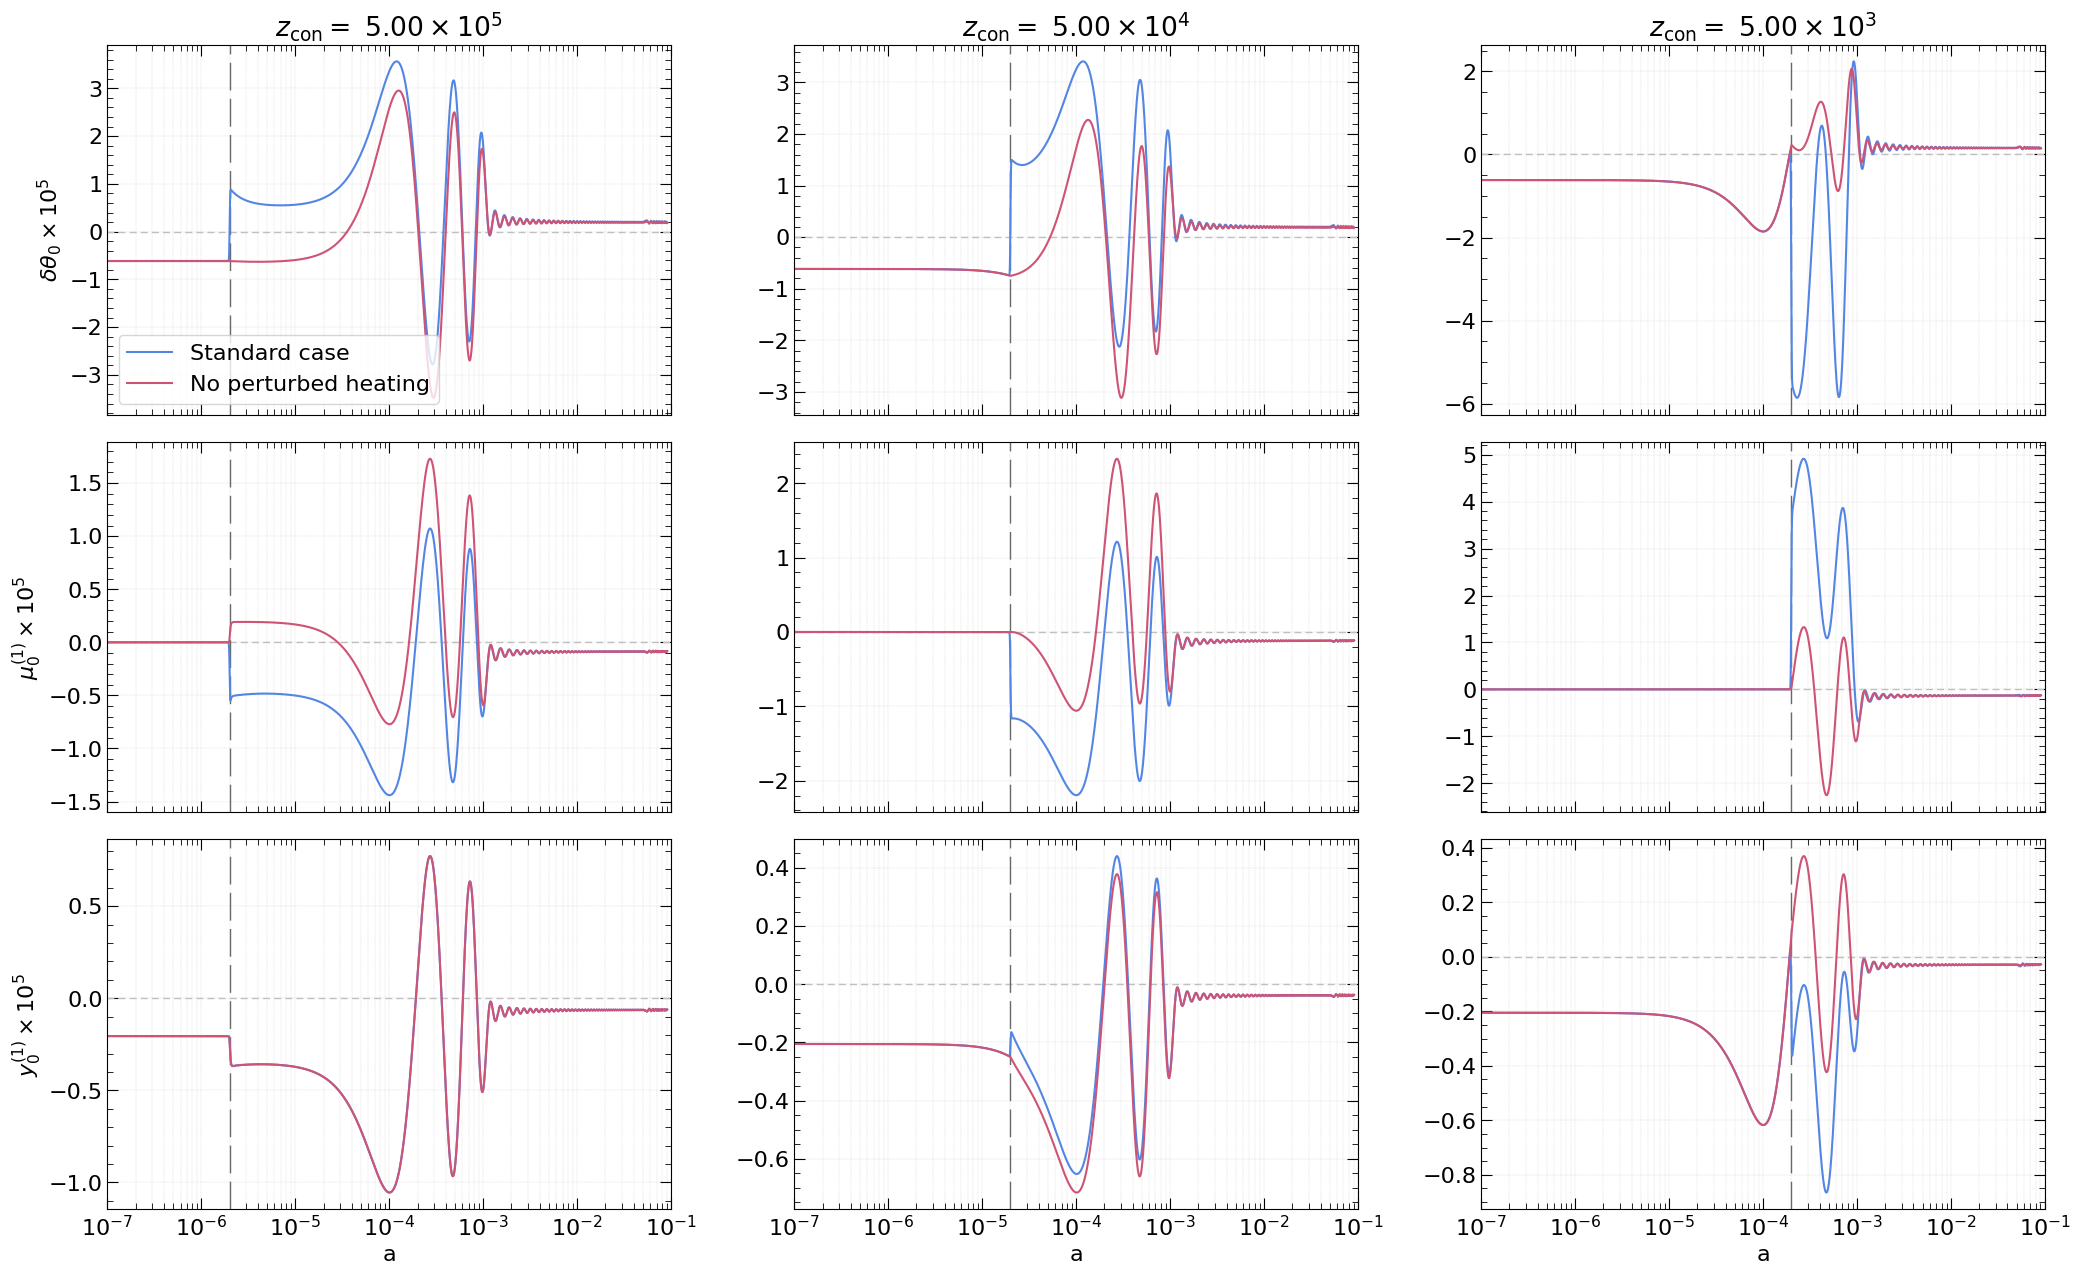

In [22]:
colors = mplt.set_colors(4, palette="dark_photons")

fig, ax1 = plt.subplots(3, 3, figsize=mplt.set_size(mplt.width*3, 1, (3,3)))
#fig.subplots_adjust(hspace=0, wspace=0)
col = 1 # choose which k you want to plot
ell_idx = 1 # choose which ell multipole you want to plot

# Apply formatting to all subplots
for ax in ax1.flat:
    mplt.set_ticks(ax)
    mplt.set_labels(ax, x_label=None, x_log=True, y_label=None, y_log=False, title=None)
    ax.axhline(y=0, color='silver', linewidth=1, linestyle=(0, (5, 3)))
    ax.set_xlim(1e-7, 1e-1)

for j in range (3):
    for i in range (len(zcon)):
        ax1[j, i].axvline(x= 1 / (1+zcon[i]), color='dimgray', linestyle=(0, (20, 6)), linewidth=1)

# Firs column theta    
#==============================================================================================================================
# ax1[0,0].plot(a[col], 4*theta[col][-1]*1e5, color=colors[0], label="Standard case", linewidth=1, linestyle="-")
# ax1[0,0].plot(a_noph[col], 4*theta_noph[col][-1]*1e5, label = "No perturbed heating", linewidth=1, color=colors[2],   linestyle="-")

ax1[0,0].plot(a_1[col], 4*theta_1[col][-1]*1e5, color=colors[0], label="Standard case",  linestyle="-")
ax1[0,0].plot(a_noph1[col], 4*theta_noph1[col][-1]*1e5, label = "No perturbed heating", color=colors[2],   linestyle="-")

ax1[0,1].plot(a_2[col], 4*theta_2[col][-1]*1e5, color=colors[0], label="Standard case", linestyle="-")
ax1[0,1].plot(a_noph2[col], 4*theta_noph2[col][-1]*1e5, label = "No perturbed heating", color=colors[2],   linestyle="-")

ax1[0,2].plot(a_3[col], 4*theta_3[col][-1]*1e5, color=colors[0], label="Standard case", linestyle="-")
ax1[0,2].plot(a_noph3[col], 4*theta_noph3[col][-1]*1e5, label = "No perturbed heating", color=colors[2],   linestyle="-")

ax1[0, 0].set_ylabel("$\\delta \\theta_0 \\times 10^5$")

# Second column mu
#==============================================================================================================================
# ax1[1, 0].plot(a[col], 1/1.401*mu[col][ell_idx]*1e5, color=colors[0], linewidth=1, linestyle="-")
# ax1[1, 0].plot(a_noph[col], 1/1.401*mu_noph[col][ell_idx]*1e5,  color=colors[2],   linewidth=1, linestyle="-")

ax1[1, 0].plot(a_1[col], 1/1.401*mu_1[col][ell_idx]*1e5, color=colors[0],   linestyle="-")
ax1[1, 0].plot(a_noph1[col], 1/1.401*mu_noph1[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[1, 1].plot(a_2[col], 1/1.401*mu_2[col][ell_idx]*1e5, color=colors[0],   linestyle="-")
ax1[1, 1].plot(a_noph2[col], 1/1.401*mu_noph2[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[1, 2].plot(a_3[col], 1/1.401*mu_3[col][ell_idx]*1e5, color=colors[0],   linestyle="-")
ax1[1, 2].plot(a_noph3[col], 1/1.401*mu_noph3[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[1, 0].set_ylabel("$\\mu^{(1)}_0 \\times 10^5$")


# Third column y
#==============================================================================================================================
# ax1[2, 0].plot(a[col], 4*y[col][ell_idx]*1e5,  color=colors[0],   linewidth=1, linestyle="-")
# ax1[2, 0].plot(a_noph[col], 4*y_noph[col][ell_idx]*1e5,  color=colors[2],   linewidth=1, linestyle="-")

ax1[2, 0].plot(a_1[col], 4*y_1[col][ell_idx]*1e5,  color=colors[0],   linestyle="-")
ax1[2, 0].plot(a_noph1[col], 4*y_noph1[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[2, 1].plot(a_2[col], 4*y_2[col][ell_idx]*1e5,  color=colors[0],   linestyle="-")
ax1[2, 1].plot(a_noph2[col], 4*y_noph2[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[2, 2].plot(a_3[col], 4*y_3[col][ell_idx]*1e5,  color=colors[0],   linestyle="-")
ax1[2, 2].plot(a_noph3[col], 4*y_noph3[col][ell_idx]*1e5,  color=colors[2],   linestyle="-")

ax1[2, 0].set_ylabel("$y^{(1)}_0 \\times 10^5$")

# Set x-labels for bottom row only
for col in range(len(zcon)):
    ax1[2, col].set_xlabel("a")

# Remove x tick labels for top two rows
for row in range(2):
    for col in range(len(zcon)):
        ax1[row, col].tick_params(labelbottom=False)
        
for i in range(len(zcon)):
    ax1[0, i].set_title(f"$z_{{\\rm con}} =$ {tools.sci_notation(zcon[i])}")

ax1[0,0].legend()

plt.tight_layout()

plt.savefig('outputs/transfer_functions_comparison.pdf', dpi=300, bbox_inches="tight")
plt.show()
